In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


*   **Pregnacies**: Συνολικός αριθμός εγκυμοσύνης της ασθενούς
*   **Glucose**: Σύνολο γλυκόζης στο αίμα της ασθενούς
*   **ΒloodPressure**: Πίεση του αίματος της ασθενούς
*   **SkinThickness**: Πάχος του δέρματος της ασθενούς
*   **Insulin**: Επίπεδα ινσουλίνης στο αίμα της ασθενούς
*   **BMI**: Δείκτης μάζας σώματος της ασθενούς
*   **DiabetePedigreeFunction**: Μαθηματικός δείκτης που κρίνει την     περίπτωση διαβήτη με βάση το οικογενειακό ιστορικό
*   **Age**: Ηλικία της ασθενούς
*   **Outcome**: Αποτελέσματα.Για τιμή 1 η ασθενής έχει διαβήτη και για 0 δεν  έχει.


In [231]:
df.describe().loc[['mean', 'std', 'min', 'max']]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Με την χρήση της συνάρητης df.describe() υπολογίζονται η μέση τιμή , η τυπική απόκλιση και η ελάχιστες και μεγίστες τιμές για τις παραπάνω κατηγορίες

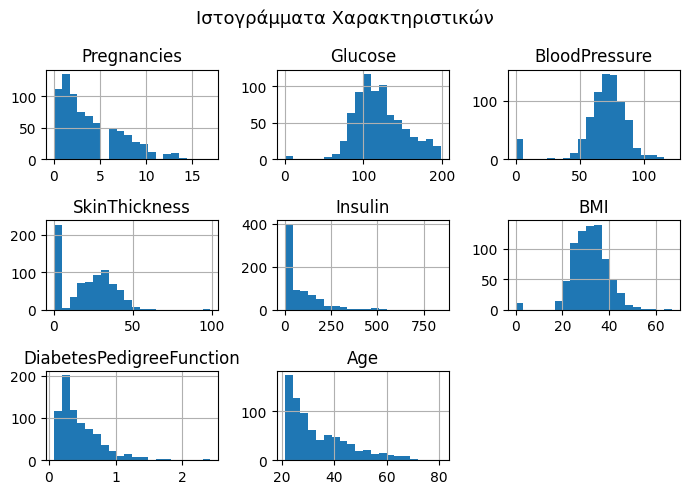

In [232]:
import matplotlib.pyplot as plt

features = df.columns.drop('Outcome')
df[features].hist(figsize=(7, 5), bins=20)

plt.suptitle('Ιστογράμματα Χαρακτηριστικών', fontsize=13)
plt.tight_layout()
plt.show()

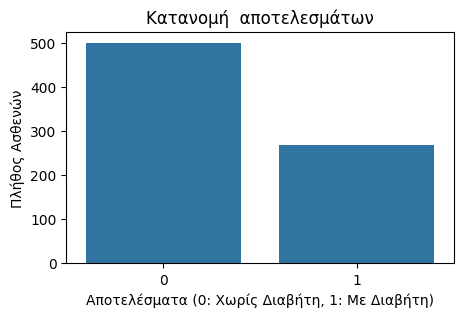

In [30]:
import seaborn as sns
plt.figure(figsize=(5, 3))
sns.countplot(x='Outcome', data=df)

plt.title('Κατανομή  αποτελεσμάτων')
plt.xlabel('Αποτελέσματα (0: Χωρίς Διαβήτη, 1: Με Διαβήτη)')
plt.ylabel('Πλήθος Ασθενών')
plt.show()

In [239]:
import numpy as np
from sklearn.model_selection import train_test_split

x = df.drop('Outcome', axis=1).values
y = df['Outcome'].values
print("Διαστάσεις του x:",x.shape)
print("Διαστάσεις του y:" ,y.shape)

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=0)

print("Πλήθος παραδειγμάτων εκπαίδευσης:", X_train.shape[0])
print("Πλήθος παραδειγμάτων επικύρωσης:", X_test.shape[0])

Διαστάσεις του x: (768, 8)
Διαστάσεις του y: (768,)
Πλήθος παραδειγμάτων εκπαίδευσης: 537
Πλήθος παραδειγμάτων επικύρωσης: 231


In [230]:
X_train_scaled =scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
geo= LogisticRegression(random_state=0)
geo.fit(X_train_scaled, y_train)
y_train_pred = geo.predict(X_train_scaled)
y_test_pred =geo.predict(X_test_scaled)
train =accuracy_score(y_train, y_train_pred)
test = accuracy_score(y_test, y_test_pred)

print(f"Ακρίβεια  Train set: ({train * 100:.2f}%)")
print(f"Ακρίβεια  Test set:({test * 100:.2f}%)")

Ακρίβεια  Train set: (82.31%)
Ακρίβεια  Test set:(78.79%)


Από τα παραπάνω παρατηρείται πως η ακρίβεια στο test set είναι ελάχιστα χαμηλότερη σε σχέση με την ακρίβεια στο train set .



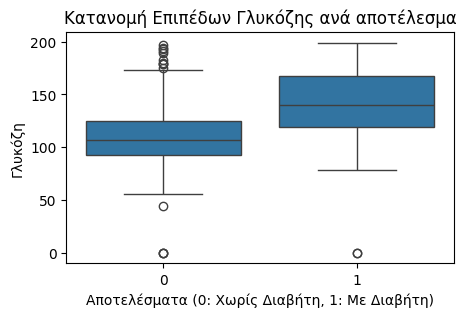

In [206]:
plt.figure(figsize=(5, 3))
sns.boxplot(x='Outcome', y='Glucose', data=df)
plt.title('Κατανομή Επιπέδων Γλυκόζης ανά αποτέλεσμα')
plt.xlabel('Αποτελέσματα (0: Χωρίς Διαβήτη, 1: Με Διαβήτη)')
plt.ylabel('Γλυκόζη')
plt.show()

Παρατηρούμε λοιπόν πως για 110 τιμή γλυκόζης έχουμε αποτέλεσμα 0 ,για  140 τιμή γλυκόζης  παίρνουμε αποτέλεσμα 1. Άρα η μέση τιμής της γλυκόζης στις ασθενείς με διαβήτη είναι αυξημένη.

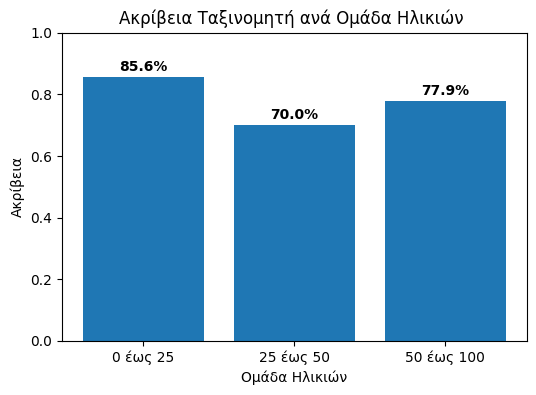

In [115]:
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)

geo = LogisticRegression(random_state=0, max_iter=1200)
geo.fit(X_train, y_train)

df_test['y_true'] = y_test
df_test['y_pred'] = geo.predict(X_test)

g1 = df_test[df_test['Age'] <= 25]
g2 = df_test[(df_test['Age'] > 25) & (df_test['Age'] <= 50)]
g3 = df_test[df_test['Age'] > 50 & (df_test['Age'] <= 100 )]

acc1 = accuracy_score(g1['y_true'], g1['y_pred'])
acc2 = accuracy_score(g2['y_true'], g2['y_pred'])
acc3 = accuracy_score(g3['y_true'], g3['y_pred'])

groups = ['0 έως 25', '25 έως 50', '50 έως 100']

plt.figure(figsize=(6,4))
bars = plt.bar(groups, accuracies)

plt.title('Ακρίβεια Ταξινομητή ανά Ομάδα Ηλικιών ')
plt.xlabel('Ομάδα Ηλικιών')
plt.ylabel('Ακρίβεια')
plt.ylim(0, 1.0)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval * 100:.1f}%", ha='center', fontweight='bold')
plt.show()

Στην συγκεκριμένη εφαρμογή , είναι χειρότερο να προβλέπεται πως ένας ασθενής δεν έχει διαβήτη, ενώ στην πραγματικότητα έχει καθώς η αρρώστια θα συνεχίσει να εξελίσσεται , γεγονός που μπορεί να οδηγήσει σε σοβαρές επιπλοκές στη υγεία της ασθενούς.

**ΜΕΡΟΣ 2**

In [139]:
input_features= ['Pregnancies', 'BloodPressure', 'BMI','Age']
arx =df[input_features].values
ary = df['Glucose'].values
X_train, X_test, y_train, y_test = train_test_split(x, y,test_size=0.30,random_state=0)

print("Διαστάσεις του x:", arx.shape)
print("Διαστάσεις του y:",ary.shape)
print("Πλήθος δειγμάτων εκπαίδευσης:",X_train.shape[0])
print("Πλήθος δειγμάτων επικύρωσης:",X_test.shape[0])

Διαστάσεις του x: (768, 4)
Διαστάσεις του y: (768,)
Πλήθος δειγμάτων εκπαίδευσης: 537
Πλήθος δειγμάτων επικύρωσης: 231


In [156]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

tan = LinearRegression()
tan.fit(X_train, y_train)
y =tan.predict(X_test)

pr =mean_absolute_error(y_test,y)
tet = mean_squared_error(y_test,y)
sun = np.sqrt(tet)

print(f"Mean Absolute Error:{pr:.2f}")
print(f"Mean Squared Error:{tet:.2f}")
print(f"Root Mean Squared Error:{sun:.2f}")

Mean Absolute Error:23.60
Mean Squared Error:929.89
Root Mean Squared Error:30.49


Το MAΕ υπολογίζει την μέση απόκλιση της πρόβλεψης σε πραγματικές μονάδες με απόρροια το αποτέλεσμα να είναι κατανοητό στους χρήστες. Αντίθεα το MSE με τη χρήση του δεν είναι ιατρικά κατανοητό. Έτσι το MAE κρίνεται καταλληλότερο

In [204]:
tom= LinearRegression()
tom.fit(Xstd, y_train)
sminmax= MinMaxScaler()
Xminmax= sminmax.fit_transform(X_train)

tom1.fit(Xminmax, y_train)
coef_df = pd.DataFrame({
    'Χαρακτηριστικα (Specs)': feature_names,
    'Συντελεστής (StandardScaler)': tom.coef_,
    'Απόλυτη Τιμή (Standardization)': np.abs(tom.coef_),
    'Συντελεστής (MinMaxScaler)': tom1.coef_,
    'Απόλυτη Τιμή (Normalization)': np.abs(tom1.coef_)
})

print(coef_df.sort_values(by='Απόλυτη Τιμή (Standardization)', ascending=False))

  Χαρακτηριστικα (Specs)  Συντελεστής (StandardScaler)  \
3                    Age                      9.214627   
2                    BMI                      7.562080   
1          BloodPressure                      0.793616   
0            Pregnancies                     -0.572175   

   Απόλυτη Τιμή (Standardization)  Συντελεστής (MinMaxScaler)  \
3                        9.214627                   46.102759   
2                        7.562080                   63.213494   
1                        0.793616                    4.978801   
0                        0.572175                   -2.859277   

   Απόλυτη Τιμή (Normalization)  
3                     46.102759  
2                     63.213494  
1                      4.978801  
0                      2.859277  


Από ότι φαίνεται η πιο σημαντική μεταβλητή είναι η ηλικία (Age).Με τη χρήση κανονικοποίησης και τυποποίησης ολά τα χαρακτηριστικά μπαίνουν στην ίδια κλίμακα. Έτσι καταλαβαίνουμε  απο την απόλυτη τιμή έχει τον μεγαλύτερο σε απόλυτη τιμή συντελεστή για την επιρροή της πρόβλεψεις της γλυκόζης.